# Imports 

In [65]:
import pandas as pd
import numpy as np
# from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, StratifiedShuffleSplit, RandomizedSearchCV
from sklearn.preprocessing import RobustScaler, MinMaxScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix
import joblib
import matplotlib.pyplot as plt
from sklearn.ensemble import AdaBoostClassifier
from sklearn.preprocessing import LabelEncoder

from elm import ELMClassifier

random_state=42

-----

# Functions

In [66]:
def train_validation_test_split(
        X, y, validation_size=0.1,
        test_size=0.1, random_state=42):
    
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=y
    )

    X_train, X_valid, y_train, y_valid = train_test_split(
        X_train, y_train,
        test_size=validation_size / (1 - test_size),
        random_state=random_state,
        stratify=y_train,
    )
    return X_train, X_valid, X_test, y_train, y_valid, y_test

In [67]:
import sklearn
sklearn.__version__

'0.20.4'

In [68]:
from scipy import stats

def confidence_interval(data, confidence=0.95):
    a = 1.0 * np.array(data)
    n = len(a)
    m, se = np.mean(a), stats.sem(a)
    h = se * stats.t.ppf((1 + confidence) / 2., n-1)
    return "{:.5f} ± {:.5f}".format(m, h)

In [69]:
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import label_binarize

def multiclass_roc_auc_score(y_true, y_pred, average="macro"):
    """
    Calculate the ROC AUC score for multiclass classification.
    
    Parameters:
        y_true (list or array): True class labels
        y_pred (list or array): Predictions, either probabilities or class labels
        average (str): 'macro' (default) averages the AUC of each class.
                       'weighted' accounts for class imbalance.
    
    Returns:
        float: ROC AUC score
    """
    # Determine the number of classes by the unique elements in the true class labels
    # y_true = np.array(y_true)
    # y_pred = np.array(y_pred)

    
    classes = np.unique(y_true)
    
    # Binarize the output labels for multiclass
    y_true_bin = label_binarize(y_true, classes=classes)
    
    # Check if y_pred is already in a one-hot encoded format
    #if y_pred.shape[1] != len(classes):
    #    y_pred = label_binarize(y_pred, classes=classes)
    
    # Compute ROC AUC for each class and average
    auc_scores = [
        roc_auc_score(y_true_bin[:, i], y_pred[:, i])
        for i in range(len(classes))
    ]
    
    if average == "macro":
        return np.mean(auc_scores)
    elif average == "weighted":
        class_counts = np.bincount(y_true)
        weights = class_counts / float(len(y_true))
        return np.average(auc_scores, weights=weights[:len(classes)])
    else:
        raise ValueError("Unknown average type. Choose 'macro' or 'weighted'")


In [70]:
def report_model_performance(model, X_train, X_valid, X_test, y_train, y_valid, y_test):
    
    accuracy_best_param_cv = np.array([model.steps[-1][-1].cv_results_["split"+str(i)+"_test_Accuracy"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    precision_best_param_cv = np.array([model.steps[-1][-1].cv_results_["split"+str(i)+"_test_Precision"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    recall_best_param_cv = np.array([model.steps[-1][-1].cv_results_["split"+str(i)+"_test_Recall"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    f1_best_param_cv = np.array([model.steps[-1][-1].cv_results_["split"+str(i)+"_test_F1"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    roc_auc_best_param_cv = np.array([model.steps[-1][-1].cv_results_["split"+str(i)+"_test_ROC-AUC"] for i in range(model.steps[-1][-1].cv.get_n_splits())])[
        :, model.steps[-1][-1].best_index_
    ]
    
    
    best_param = model.steps[-1][-1].best_params_
    print "Best parameters:" + str(best_param)
    print "Cross Validation accuracy Array:" + str(accuracy_best_param_cv)
    print "Validation accuracy:" + confidence_interval(accuracy_best_param_cv)
    
    print "Cross Validation precision Array:" + str(precision_best_param_cv)
    print "Validation precision:" + confidence_interval(precision_best_param_cv)
    
    print "Cross Validation recall Array:" + str(recall_best_param_cv)
    print "Validation recall:" + confidence_interval(recall_best_param_cv)
    
    print "Cross Validation f1 Array:" + str(f1_best_param_cv)
    print "Validation f1:" + confidence_interval(f1_best_param_cv)
    
    print "Cross Validation roc_auc Array:" + str(roc_auc_best_param_cv)
    print "Validation roc_auc:" + confidence_interval(roc_auc_best_param_cv)
    
    print() 
    print()
    y_train_pred = model.predict(X_train)
    y_train_pred_proba = model.predict_proba(X_train)
    y_valid_pred = model.predict(X_valid)
    y_valid_pred_proba = model.predict_proba(X_valid)
    y_test_pred = model.predict(X_test)
    y_test_pred_proba = model.predict_proba(X_test)
    print("===> Training performance")
    print(classification_report(y_train, y_train_pred, digits=5))
    print("Training ROC-AUC:" + str(multiclass_roc_auc_score(y_train, y_train_pred_proba)).format(5))
    
    print("===> Validation performance")
    print(classification_report(y_valid, y_valid_pred, digits=5))
    print("Validation ROC-AUC:" + str(multiclass_roc_auc_score(y_valid, y_valid_pred_proba)).format(5))
    print("===> Test performance")
    print(classification_report(y_test, y_test_pred, digits=5))
    print("Testing ROC-AUC:" + str(multiclass_roc_auc_score(y_test, y_test_pred_proba)).format(5))
    
    plt.figure(figsize=(30, 30))
    with sns.plotting_context("notebook", font_scale=1.5):
        conf_matrix = confusion_matrix(y_train, y_train_pred)
        sns.heatmap(conf_matrix, annot=True, fmt="d")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title("Train Confusion Matrix")
        plt.show()

    with sns.plotting_context("notebook", font_scale=1.5):
        conf_matrix = confusion_matrix(y_valid, y_valid_pred)
        sns.heatmap(conf_matrix, annot=True, fmt="d")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title("Validation Confusion Matrix")
        plt.show()
        
    with sns.plotting_context("notebook", font_scale=1.5):
        conf_matrix = confusion_matrix(y_test, y_test_pred)
        sns.heatmap(conf_matrix, annot=True, fmt="d")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title("Test Confusion Matrix")
        plt.show()

In [71]:
def save_model(model, model_name):
    joblib.dump(model, str(model_name) + ".joblib")

# Read Dataset

In [72]:
X = pd.read_csv("wine.csv", sep=";")

In [73]:
y = X[X.columns[-1]]
X = X.drop(columns=[X.columns[-1]])

# Descritive statistics

In [74]:
X.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000


In [75]:
y.value_counts(normalize=True)

6    0.436509
5    0.329075
7    0.166077
4    0.033246
8    0.029706
3    0.004618
9    0.000770
Name: quality, dtype: float64

## Split Dataset

In [76]:
X_train, X_valid, X_test, y_train, y_valid, y_test = train_validation_test_split(
    X, y, validation_size=0.1, test_size=0.1, random_state=random_state
)

In [77]:
X_train.shape, X_valid.shape, X_test.shape

((5197, 11), (650, 11), (650, 11))

# Pre-processing

## Scaling the data

In [78]:
scaler_elm = MinMaxScaler()

# Model

## ELM

In [79]:
from random_layer import RandomLayer

In [80]:
from sklearn.metrics import make_scorer

cv = StratifiedShuffleSplit(n_splits=50, test_size=0.2, random_state=random_state)
elm = ELMClassifier()
roc_auc_scorer = make_scorer(multiclass_roc_auc_score, needs_proba=True)

scoring = {
    "Accuracy": "accuracy", "ROC-AUC": roc_auc_scorer,
    "Precision": "precision_macro", "Recall": "recall_macro", "F1": "f1_macro",
}


elm_opt = RandomizedSearchCV(
    elm,
    {
        "n_hidden": (10, 100),
        "activation_func": ['multiquadric', 'hardlim', 'tribas', 'tanh', 'sigmoid', 'sine', 'softlim', 'gaussian', 'inv_multiquadric', 'inv_tribas'],
        "alpha": (0.5, 1),
    },
    n_iter=25,
    cv=cv,
    n_jobs=-1,
    verbose=2,
    scoring=scoring,
    refit="Accuracy",
    random_state=random_state,
)

pipe_elm = Pipeline([("scaler", scaler_elm), ("elm", elm_opt)])

In [81]:
pipe_elm.fit(X_train, y_train)

Fitting 50 folds for each of 25 candidates, totalling 1250 fits


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  17 tasks      | elapsed:    8.8s
[Parallel(n_jobs=-1)]: Done 138 tasks      | elapsed:   20.0s
[Parallel(n_jobs=-1)]: Done 341 tasks      | elapsed:   26.9s
[Parallel(n_jobs=-1)]: Done 624 tasks      | elapsed:   48.4s
[Parallel(n_jobs=-1)]: Done 989 tasks      | elapsed:  1.2min
[Parallel(n_jobs=-1)]: Done 1250 out of 1250 | elapsed:  1.5min finished


Pipeline(memory=None,
     steps=[('scaler', MinMaxScaler(copy=True, feature_range=(0, 1))), ('elm', RandomizedSearchCV(cv=StratifiedShuffleSplit(n_splits=50, random_state=42, test_size=0.2,
            train_size=None),
          error_score='raise-deprecating',
          estimator=ELMClassifier(activation_args=None, activat...', 'Precision': 'precision_macro', 'F1': 'f1_macro', 'Accuracy': 'accuracy'},
          verbose=2))])

In [82]:
pipe_elm.score(X_test, y_test)

0.5153846153846153

In [83]:
pipe_elm.steps[-1][-1].cv_results_

{'mean_fit_time': array([0.29418002, 0.02688   , 0.45706001, 0.01410001, 0.00577999,
        0.01594   , 0.34291998, 0.23889999, 0.27708001, 0.01736   ,
        0.29149999, 0.25596   , 0.55074002, 0.36735999, 0.01451999,
        0.00574002, 0.42728   , 0.01634   , 0.00626002, 0.33706   ,
        0.30922   , 0.27171997, 0.33172002, 0.34903997, 0.33954001]),
 'mean_score_time': array([0.19287999, 0.01374   , 0.44128002, 0.01049999, 0.00912   ,
        0.01938001, 0.20646001, 0.19013999, 0.22671999, 0.00940001,
        0.22516002, 0.32341998, 0.46593999, 0.3165    , 0.00966002,
        0.0092    , 0.26314001, 0.01174   , 0.00901999, 0.25510002,
        0.20313999, 0.19812001, 0.26003997, 0.28676   , 0.27345999]),
 'mean_test_Accuracy': array([0.55682692, 0.52963462, 0.55682692, 0.48892308, 0.43751923,
        0.518     , 0.43761538, 0.55034615, 0.55421154, 0.45782692,
        0.43776923, 0.01611538, 0.55140385, 0.55944231, 0.52126923,
        0.37080769, 0.55338462, 0.46336538, 0.5285    

In [84]:
pipe_elm.predict(X_valid)

array([6, 6, 7, 6, 5, 5, 5, 6, 6, 5, 5, 6, 5, 6, 6, 6, 6, 5, 6, 6, 6, 6,
       6, 6, 6, 6, 5, 6, 5, 5, 6, 5, 5, 7, 5, 6, 7, 5, 5, 6, 5, 6, 6, 6,
       6, 7, 7, 5, 6, 6, 5, 5, 6, 6, 5, 5, 5, 5, 6, 7, 6, 6, 5, 5, 6, 7,
       5, 5, 5, 6, 6, 5, 6, 6, 5, 7, 6, 5, 6, 5, 6, 6, 6, 7, 5, 5, 5, 6,
       6, 6, 5, 5, 6, 6, 6, 5, 6, 6, 6, 5, 7, 5, 6, 5, 6, 6, 6, 6, 7, 6,
       6, 6, 6, 6, 6, 6, 5, 6, 6, 6, 5, 5, 6, 6, 5, 5, 6, 6, 6, 5, 5, 6,
       6, 6, 5, 6, 5, 5, 6, 5, 6, 5, 6, 6, 5, 6, 7, 5, 6, 6, 6, 6, 6, 7,
       5, 6, 5, 5, 6, 6, 6, 5, 6, 6, 5, 6, 5, 6, 6, 6, 6, 6, 5, 6, 6, 6,
       6, 6, 5, 5, 6, 6, 6, 5, 6, 6, 6, 6, 6, 5, 6, 6, 6, 5, 6, 7, 5, 6,
       6, 5, 5, 5, 5, 6, 5, 6, 5, 6, 5, 5, 7, 7, 5, 6, 6, 5, 6, 5, 6, 6,
       5, 6, 5, 5, 6, 5, 6, 5, 6, 6, 6, 5, 6, 5, 6, 6, 6, 6, 6, 5, 6, 6,
       5, 5, 6, 5, 6, 6, 5, 6, 6, 5, 6, 6, 5, 5, 6, 6, 6, 6, 6, 6, 5, 5,
       6, 6, 6, 6, 6, 5, 5, 5, 6, 6, 5, 6, 7, 6, 7, 6, 5, 6, 5, 5, 5, 7,
       6, 6, 6, 6, 5, 5, 5, 5, 5, 6, 5, 6, 6, 6, 5,

Best parameters:{'alpha': 1, 'activation_func': 'gaussian', 'n_hidden': 100}
Cross Validation accuracy Array:[0.56057692 0.55769231 0.55384615 0.56826923 0.55096154 0.56634615
 0.58173077 0.55192308 0.59326923 0.54807692 0.55673077 0.57115385
 0.54423077 0.55096154 0.56923077 0.56730769 0.53173077 0.55576923
 0.56153846 0.56442308 0.56923077 0.54615385 0.54903846 0.54807692
 0.55961538 0.56346154 0.57596154 0.56442308 0.55576923 0.55288462
 0.55288462 0.55480769 0.55       0.55480769 0.56826923 0.56634615
 0.55384615 0.55384615 0.56634615 0.54807692 0.53269231 0.57403846
 0.55384615 0.56442308 0.57211538 0.57115385 0.56057692 0.56153846
 0.55865385 0.56346154]
Validation accuracy:0.55944 ± 0.00320
Cross Validation precision Array:[0.23499047 0.2335735  0.23182154 0.30261135 0.23115195 0.31098647
 0.25172574 0.22972349 0.25718908 0.23227318 0.22959262 0.23915766
 0.2343022  0.23443593 0.24884431 0.23982501 0.22644294 0.23944076
 0.23837808 0.24605496 0.23749283 0.3769124  0.30452522 0.2

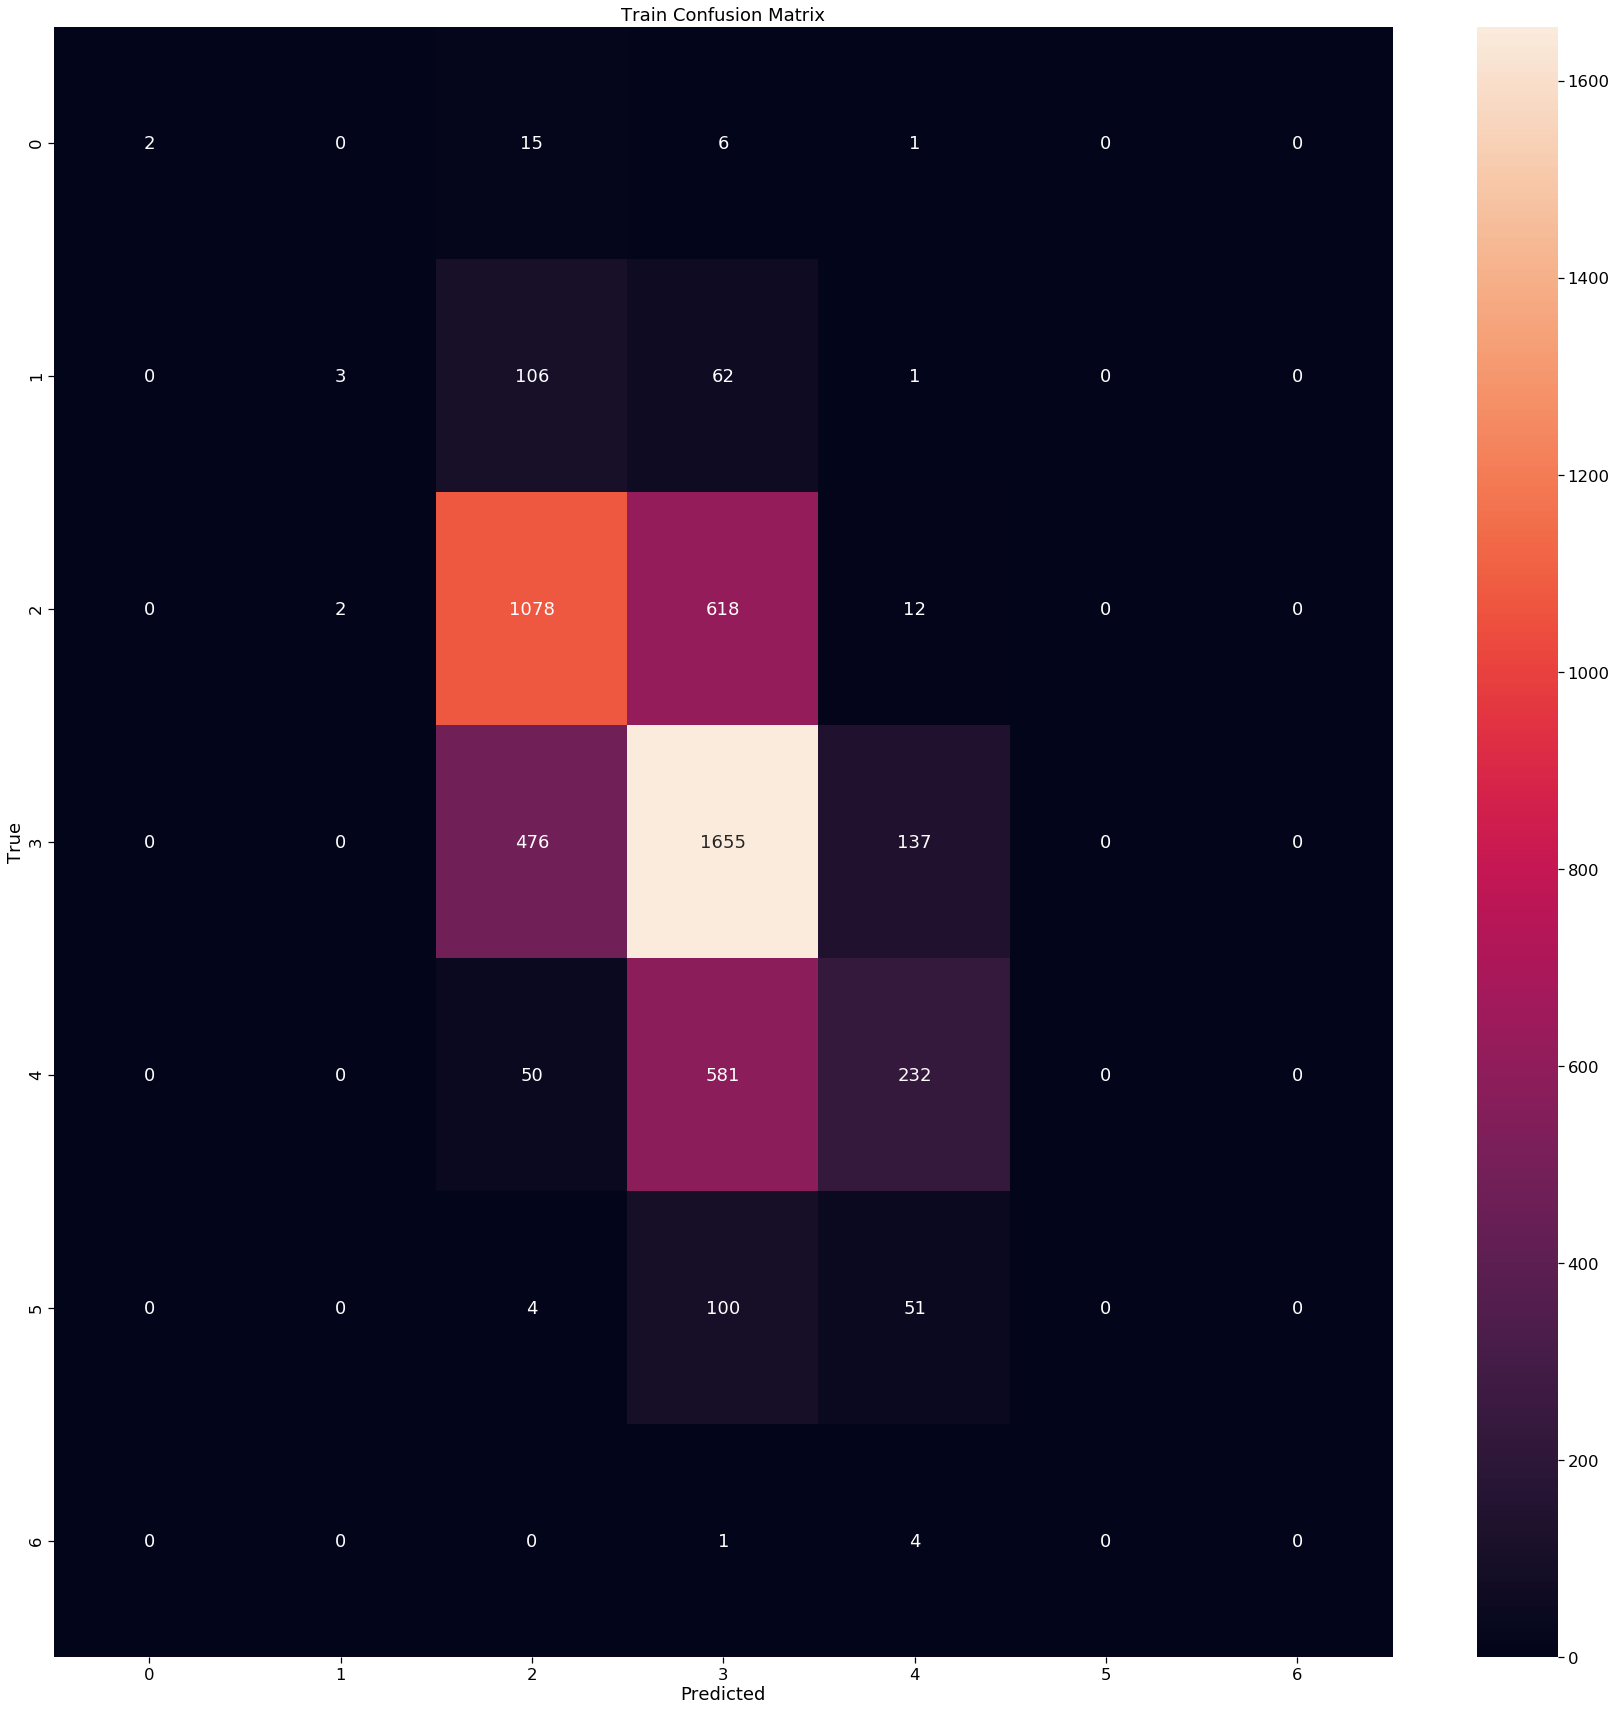

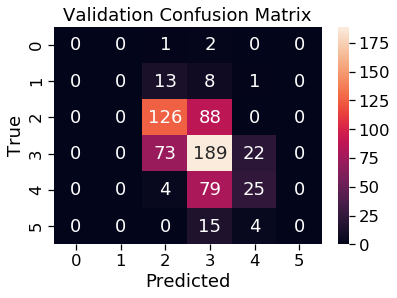

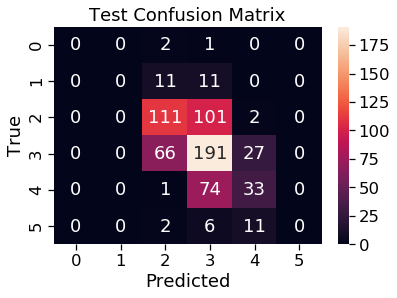

In [85]:
report_model_performance(pipe_elm, X_train, X_valid, X_test, y_train, y_valid, y_test)

In [86]:
save_model(pipe_elm, "elm")